<a href="https://colab.research.google.com/github/alelopez9411-ux/proyecto-marketing-analytics/blob/main/notebooks/01_ga4_adquisicion_embudo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import auth
auth.authenticate_user()
from google.cloud import bigquery
import pandas as pd

client = bigquery.Client(project="olist-logistica")

def sql(consulta):
    return client.query(consulta).to_dataframe()

sql("""
SELECT MIN(event_date) AS primer_dia,
       MAX(event_date) AS ultimo_dia,
       COUNT(*) AS eventos,
       COUNT(DISTINCT user_pseudo_id) AS usuarios
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
""")

,primer_dia,ultimo_dia,eventos,usuarios
0,20201101,20210131,4295584,270154


In [2]:
sql("""
SELECT event_name,
       COUNT(*) AS eventos,
       COUNT(DISTINCT user_pseudo_id) AS usuarios
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
GROUP BY event_name
ORDER BY eventos DESC
""")

,event_name,eventos,usuarios
0,page_view,1350428,269792
1,user_engagement,1058721,213004
2,scroll,493072,138098
3,view_item,386068,61252
4,session_start,354970,267116
5,first_visit,257462,257314
6,view_promotion,190104,102443
7,add_to_cart,58543,12545
8,begin_checkout,38757,9715
9,select_item,31007,13180


In [3]:
pasos = ["session_start", "view_item", "add_to_cart", "begin_checkout",
         "add_shipping_info", "add_payment_info", "purchase"]

embudo = sql(f"""
SELECT event_name AS paso,
       COUNT(DISTINCT user_pseudo_id) AS usuarios
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
WHERE event_name IN UNNEST({pasos})
GROUP BY paso
""")

embudo["orden"] = embudo["paso"].map({p: i for i, p in enumerate(pasos)})
embudo = embudo.sort_values("orden").reset_index(drop=True)
embudo["pct_del_anterior"] = (embudo["usuarios"] / embudo["usuarios"].shift(1) * 100).round(1)
embudo["pct_del_inicio"] = (embudo["usuarios"] / embudo["usuarios"].iloc[0] * 100).round(2)
embudo

,paso,usuarios,orden,pct_del_anterior,pct_del_inicio
0,session_start,267116,0,<NA>,100.0
1,view_item,61252,1,22.9,22.93
2,add_to_cart,12545,2,20.5,4.7
3,begin_checkout,9715,3,77.4,3.64
4,add_shipping_info,9714,4,100.0,3.64
5,add_payment_info,5751,5,59.2,2.15
6,purchase,4419,6,76.8,1.65


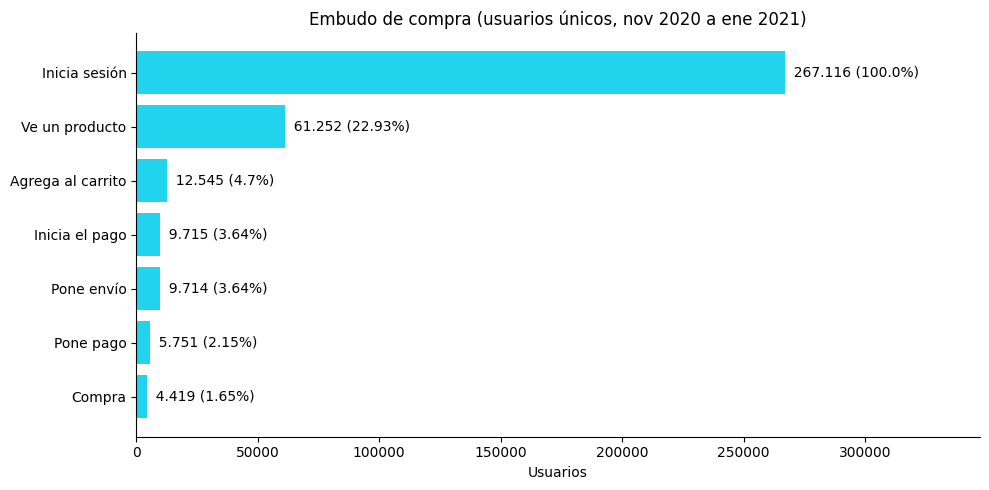

In [4]:
import matplotlib.pyplot as plt

etiquetas = ["Inicia sesión", "Ve un producto", "Agrega al carrito",
             "Inicia el pago", "Pone envío", "Pone pago", "Compra"]

fig, ax = plt.subplots(figsize=(10, 5))
usuarios = embudo["usuarios"][::-1].tolist()
pcts = embudo["pct_del_inicio"][::-1].tolist()
ax.barh(etiquetas[::-1], usuarios, color="#22D3EE")
for i, (u, p) in enumerate(zip(usuarios, pcts)):
    ax.text(u, i, f"  {u:,} ({p}%)".replace(",", "."), va="center")
ax.set_xlim(0, max(usuarios) * 1.3)
ax.set_title("Embudo de compra (usuarios únicos, nov 2020 a ene 2021)")
ax.set_xlabel("Usuarios")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("embudo.png", dpi=150)
plt.show()

In [6]:
# Formatear la tabla de fuentes de tráfico con un estilo ejecutivo
fuentes_presentacion = fuentes.copy()

# Renombrar columnas para reporte
fuentes_presentacion.columns = [
    'Fuente', 'Medio', 'Usuarios Únicos', 'Compradores',
    'Ingresos (USD)', 'Tasa de Conversión (%)'
]

# Aplicar estilos visuales
tabla_ejecutiva = fuentes_presentacion.style\
    .format({
        'Usuarios Únicos': '{:,.0f}',
        'Compradores': '{:,.0f}',
        'Ingresos (USD)': '${:,.0f}',
        'Tasa de Conversión (%)': '{:.2f}%'
    })\
    .background_gradient(subset=['Tasa de Conversión (%)'], cmap='YlGn')\
    .background_gradient(subset=['Ingresos (USD)'], cmap='Blues')\
    .hide(axis='index')\
    .set_properties(**{
        'text-align': 'center',
        'font-family': 'DejaVu Sans, sans-serif',
        'border': '1px solid #e0e0e0'
    })\
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#1e293b'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]}
    ])

display(tabla_ejecutiva)

Fuente,Medio,Usuarios Únicos,Compradores,Ingresos (USD),Tasa de Conversión (%)
google,organic,"103,487","1,229","$95,775",1.19%
(direct),(none),"75,951","1,054","$79,650",1.39%
,,"51,037",499,"$35,470",0.98%
,referral,"32,880",468,"$37,000",1.42%
shop.googlemerchandisestore.com,referral,"26,065",568,"$46,521",2.18%
(data deleted),(data deleted),"17,948",680,"$50,064",3.79%
google,cpc,"15,527",152,"$9,056",0.98%
,organic,"10,095",97,"$8,232",0.96%
,(data deleted),393,9,$397,2.29%
(data deleted),referral,3,0,$0,0.00%


In [7]:
fuentes = sql("""
WITH usuarios AS (
  SELECT user_pseudo_id,
         ARRAY_AGG(STRUCT(traffic_source.source AS fuente, traffic_source.medium AS medio)
                   ORDER BY event_timestamp LIMIT 1)[OFFSET(0)] AS canal
  FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
  GROUP BY user_pseudo_id
),
compras AS (
  SELECT user_pseudo_id,
         SUM(ecommerce.purchase_revenue_in_usd) AS ingresos
  FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
  WHERE event_name = 'purchase'
  GROUP BY user_pseudo_id
)
SELECT u.canal.fuente AS fuente,
       u.canal.medio AS medio,
       COUNT(*) AS usuarios,
       COUNTIF(c.user_pseudo_id IS NOT NULL) AS compradores,
       ROUND(IFNULL(SUM(c.ingresos), 0), 0) AS ingresos_usd
FROM usuarios u
LEFT JOIN compras c ON u.user_pseudo_id = c.user_pseudo_id
GROUP BY fuente, medio
ORDER BY usuarios DESC
LIMIT 15
""")

fuentes["conversion_pct"] = (fuentes["compradores"] / fuentes["usuarios"] * 100).round(2)
fuentes["ingreso_por_usuario"] = (fuentes["ingresos_usd"] / fuentes["usuarios"]).round(2)
fuentes

,fuente,medio,usuarios,compradores,ingresos_usd,conversion_pct,ingreso_por_usuario
0,google,organic,93041,1428,113013.0,1.53,1.21
1,(direct),(none),64109,1011,83743.0,1.58,1.31
2,<Other>,<Other>,47100,680,52248.0,1.44,1.11
3,<Other>,referral,25256,414,33454.0,1.64,1.32
4,shop.googlemerchandisestore.com,referral,14763,330,28616.0,2.24,1.94
5,google,cpc,14282,218,18321.0,1.53,1.28
6,<Other>,organic,8701,129,10760.0,1.48,1.24
7,(data deleted),(data deleted),2848,206,21901.0,7.23,7.69
8,<Other>,(data deleted),52,3,109.0,5.77,2.1
9,google,<Other>,1,0,0.0,0.0,0.0


In [11]:
chi2, p, gl, esperados = chi2_contingency(tabla.astype(float).values)
print(f"chi-cuadrado = {chi2:.1f} | grados de libertad = {gl} | p = {p:.4f}")

chi-cuadrado = 49.1 | grados de libertad = 6 | p = 0.0000


In [13]:
import numpy as np
from statsmodels.stats.multitest import multipletests

principales = principales.reset_index(drop=True)
tot_u = float(principales["usuarios"].sum())
tot_c = float(principales["compradores"].sum())

filas = []
for _, r in principales.iterrows():
    u, c = float(r["usuarios"]), float(r["compradores"])
    t = np.array([[c, u - c],
                  [tot_c - c, (tot_u - tot_c) - (u - c)]])
    _, p, _, _ = chi2_contingency(t)
    filas.append({"canal": r["fuente"] + " / " + r["medio"],
                  "conversion_pct": round(c / u * 100, 2),
                  "resto_pct": round((tot_c - c) / (tot_u - u) * 100, 2),
                  "p": p})

res = pd.DataFrame(filas)
res["p_holm"] = multipletests(res["p"], method="holm")[1]
res["significativo"] = res["p_holm"] < 0.05
res.round(4)

,canal,conversion_pct,resto_pct,p,p_holm,significativo
0,google / organic,1.53,1.60,0.2255,1.0000,False
1,(direct) / (none),1.58,1.57,0.9827,1.0000,False
2,<Other> / <Other>,1.44,1.60,0.0122,0.0733,False
3,<Other> / referral,1.64,1.57,0.4061,1.0000,False
4,shop.googlemerchandisestore.com / referral,2.24,1.54,0.0000,0.0000,True
5,google / cpc,1.53,1.58,0.6543,1.0000,False
6,<Other> / organic,1.48,1.58,0.5078,1.0000,False


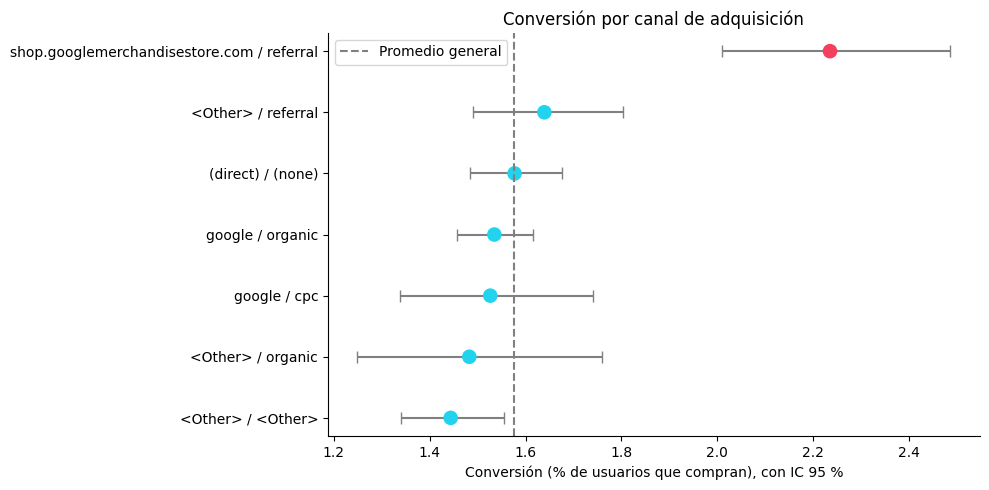

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

g = principales.copy()
g["canal"] = g["fuente"] + " / " + g["medio"]
comp = g["compradores"].astype(float).to_numpy()
usu = g["usuarios"].astype(float).to_numpy()
g["conv"] = comp / usu * 100
bajo, alto = proportion_confint(comp, usu, method="wilson")
g["bajo"], g["alto"] = bajo * 100, alto * 100
g = g.sort_values("conv").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(g))
colores = ["#F43F5E" if "googlemerchandisestore" in c else "#22D3EE" for c in g["canal"]]
ax.errorbar(g["conv"], y, xerr=[g["conv"] - g["bajo"], g["alto"] - g["conv"]],
            fmt="none", ecolor="gray", capsize=4, zorder=1)
ax.scatter(g["conv"], y, c=colores, s=90, zorder=2)
ax.axvline(tot_c / tot_u * 100, color="gray", linestyle="--", label="Promedio general")
ax.set_yticks(y)
ax.set_yticklabels(g["canal"])
ax.set_xlabel("Conversión (% de usuarios que compran), con IC 95 %")
ax.set_title("Conversión por canal de adquisición")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("conversion_canales.png", dpi=150)
plt.show()

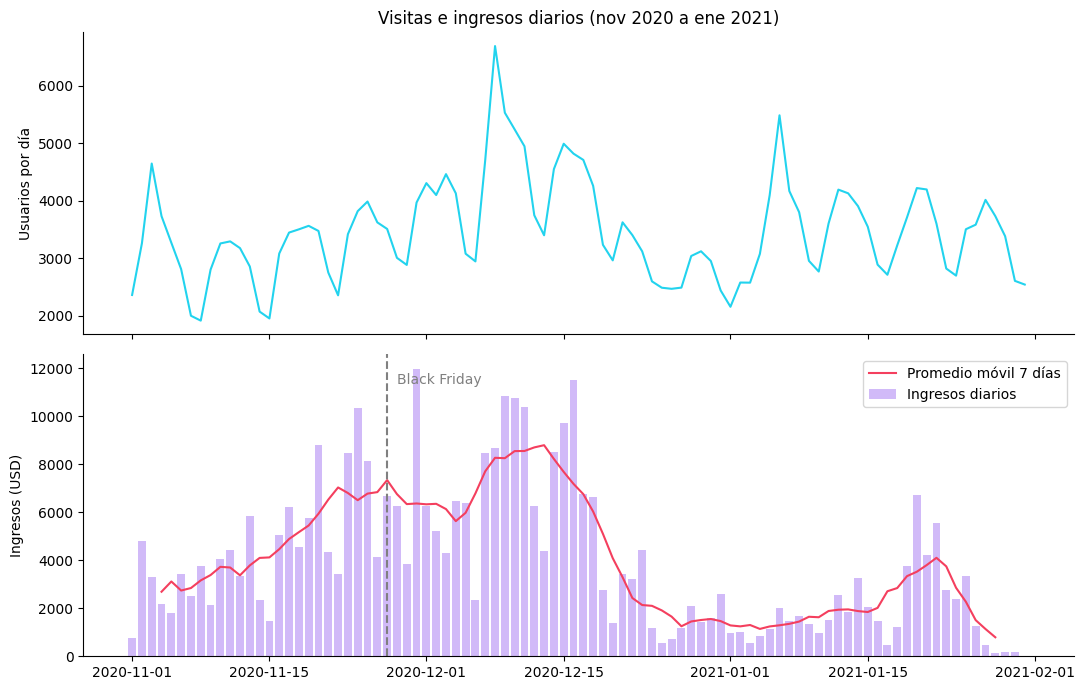

In [15]:
diario = sql("""
SELECT PARSE_DATE('%Y%m%d', event_date) AS fecha,
       COUNT(DISTINCT user_pseudo_id) AS usuarios,
       COUNTIF(event_name = 'purchase') AS compras,
       ROUND(SUM(IF(event_name = 'purchase', ecommerce.purchase_revenue_in_usd, 0)), 0) AS ingresos_usd
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
GROUP BY fecha
ORDER BY fecha
""")

diario["fecha"] = pd.to_datetime(diario["fecha"])
for col in ["usuarios", "compras", "ingresos_usd"]:
    diario[col] = diario[col].astype(float)
diario["ingresos_7d"] = diario["ingresos_usd"].rolling(7, center=True).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.plot(diario["fecha"], diario["usuarios"], color="#22D3EE")
ax1.set_ylabel("Usuarios por día")
ax1.set_title("Visitas e ingresos diarios (nov 2020 a ene 2021)")
ax2.bar(diario["fecha"], diario["ingresos_usd"], color="#7C3AED", alpha=0.35, label="Ingresos diarios")
ax2.plot(diario["fecha"], diario["ingresos_7d"], color="#F43F5E", label="Promedio móvil 7 días")
ax2.set_ylabel("Ingresos (USD)")
ax2.axvline(pd.Timestamp("2020-11-27"), color="gray", linestyle="--")
ax2.text(pd.Timestamp("2020-11-28"), ax2.get_ylim()[1] * 0.9, "Black Friday", color="gray")
ax2.legend()
for a in (ax1, ax2):
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("serie_diaria.png", dpi=150)
plt.show()

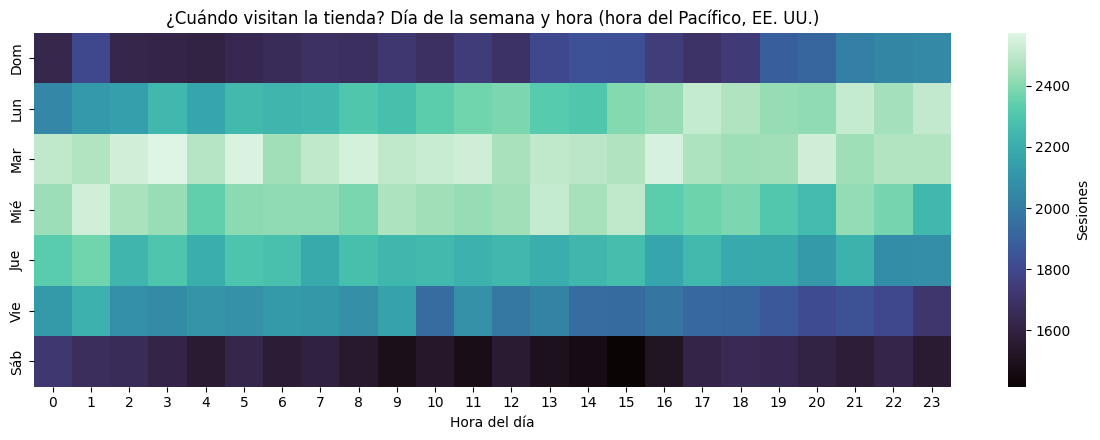

In [25]:
import seaborn as sns

calor = sql("""
SELECT EXTRACT(DAYOFWEEK FROM TIMESTAMP_MICROS(event_timestamp) AT TIME ZONE "America/Los_Angeles") AS dia,
       EXTRACT(HOUR FROM TIMESTAMP_MICROS(event_timestamp) AT TIME ZONE "America/Los_Angeles") AS hora,
       COUNTIF(event_name = 'session_start') AS sesiones
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
GROUP BY dia, hora
""")

calor =calor.astype(float)
matriz = calor.pivot(index="dia", columns="hora", values="sesiones")
matriz.index = ["Dom", "Lun", "Mar", "Mié", "Jue", "Vie", "Sáb"]
matriz.columns = matriz.columns.astype(int)

plt.figure(figsize=(12, 4.5))
sns.heatmap(matriz, cmap="mako", cbar_kws={"label": "Sesiones"})
plt.title("¿Cuándo visitan la tienda? Día de la semana y hora (hora del Pacífico, EE. UU.)")
plt.xlabel("Hora del día")
plt.ylabel("")
plt.tight_layout()
plt.savefig("mapa_calor.png", dpi=150)
plt.show()
